In [1]:
import os
if os.getenv("CUDA_VISIBLE_DEVICES") is None:
    gpu_num = 2 # Use "" to use the CPU
    os.environ["CUDA_VISIBLE_DEVICES"] = f"{gpu_num}"
    print(f"Using GPU {gpu_num}")
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
    except RuntimeError as e:
        print(e)
# Avoid warnings from TensorFlow
tf.get_logger().setLevel('ERROR')

import pandas as pd
from data_preprocessing import preprocess_data, preprocess_data_channel
from mlp.mlp_model import train_mlp, train_mlp_channel
from evaluation import print_metrics, get_metrics
from visualization import plot_confusion_matrix, plot_roc_curve
from ml_algorithms import train_knn, train_svm, train_rf

Using GPU 2


E0000 00:00:1747137431.210155 4106290 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1747137431.216464 4106290 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Using GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Full Dataset NLOS/LOS Classification
====================================

In [2]:
# Load the datasets
# df_tdl_cdl = pd.read_csv("dataset_tdl_cdl_training_siso.csv")
# df_tdl_cdl_test = pd.read_csv("dataset_tdl_cdl_testing.csv")

df_tdl_cdl_siso = pd.read_csv("dataset_tdl_cdl_training_siso.csv")
df_tdl_cdl_siso_test = pd.read_csv("dataset_tdl_cdl_testing.csv")
df_tdl_cdl_mimo = pd.read_csv("dataset_tdl_cdl_training_mimo.csv")
df_tdl_cdl_mimo_test = pd.read_csv("dataset_tdl_cdl_testing_mimo.csv")
df_tdl_cdl_0db_siso_test = pd.read_csv("dataset_tdl_cdl_0db_siso.csv")
df_tdl_cdl_0db_mimo_test = pd.read_csv("dataset_tdl_cdl_0db_mimo.csv")
# 5db
df_tdl_cdl_5db_siso_test = pd.read_csv("dataset_tdl_cdl_5db_siso.csv")
df_tdl_cdl_5db_mimo_test = pd.read_csv("dataset_tdl_cdl_5db_mimo.csv")
# 10db
df_tdl_cdl_10db_siso_test = pd.read_csv("dataset_tdl_cdl_10db_siso.csv")
df_tdl_cdl_10db_mimo_test = pd.read_csv("dataset_tdl_cdl_10db_mimo.csv")
# 15db
df_tdl_cdl_15db_siso_test = pd.read_csv("dataset_tdl_cdl_15db_siso.csv")
df_tdl_cdl_15db_mimo_test = pd.read_csv("dataset_tdl_cdl_15db_mimo.csv")

# df_sionna_mimo_los = pd.read_csv("dataset/dataset_sionna_mimo_los.csv")
# df_sionna_mimo_los_test = pd.read_csv("dataset/dataset_sionna_mimo_los_test.csv")
# df_sionna_mimo_nlos = pd.read_csv("dataset_sionna_mimo_nlos.csv")
# df_sionna_mimo_nlos_test = pd.read_csv("dataset_sionna_mimo_nlos_test.csv")
# df_sionna_siso_los = pd.read_csv("dataset_sionna_siso_los.csv")
# df_sionna_siso_los_test = pd.read_csv("dataset_sionna_siso_los_test.csv")
# df_sionna_siso_nlos = pd.read_csv("temporary_data/dataset_sionna_siso_nlos.csv")
# df_sionna_siso_nlos_test = pd.read_csv("temporary_data/dataset_sionna_siso_nlos_test.csv")


# Make the dataset for tdl only and cdl only (based on the column name model_type)
# df_tdl = df_tdl_cdl[df_tdl_cdl['model_type'] == 'tdl']
# df_cdl = df_tdl_cdl[df_tdl_cdl['model_type'] == 'cdl']
# df_tdl_test = df_tdl_cdl_test[df_tdl_cdl_test['model_type'] == 'tdl']
# df_cdl_test = df_tdl_cdl_test[df_tdl_cdl_test['model_type'] == 'cdl']
# nlos_test.csv")

# # concatenate the datasets
# df_sionna_mimo = pd.concat([df_sionna_mimo_los, df_sionna_mimo_nlos])
# df_sionna_mimo_test = pd.concat([df_sionna_mimo_los_test, df_sionna_mimo_nlos_test])



# # concatenate the datasets
# df_sionna_siso = pd.concat([df_sionna_siso_los, df_sionna_siso_nlos])
# df_sionna_siso_test = pd.concat([df_sionna_siso_los_test, df_sionna_siso_nlos_test])



df_tdl_siso = df_tdl_cdl_siso[df_tdl_cdl_siso['model_type'] == 'tdl']
df_cdl_siso = df_tdl_cdl_siso[df_tdl_cdl_siso['model_type'] == 'cdl']
df_tdl_siso_test = df_tdl_cdl_siso_test[df_tdl_cdl_siso_test['model_type'] == 'tdl']
df_cdl_siso_test = df_tdl_cdl_siso_test[df_tdl_cdl_siso_test['model_type'] == 'cdl']
df_tdl_mimo = df_tdl_cdl_mimo[df_tdl_cdl_mimo['model_type'] == 'tdl']
df_cdl_mimo = df_tdl_cdl_mimo[df_tdl_cdl_mimo['model_type'] == 'cdl']
df_tdl_mimo_test = df_tdl_cdl_mimo_test[df_tdl_cdl_mimo_test['model_type'] == 'tdl']
df_cdl_mimo_test = df_tdl_cdl_mimo_test[df_tdl_cdl_mimo_test['model_type'] == 'cdl']
df_tdl_0db_siso_test = df_tdl_cdl_0db_siso_test[df_tdl_cdl_0db_siso_test['model_type'] == 'tdl']
df_cdl_0db_siso_test = df_tdl_cdl_0db_siso_test[df_tdl_cdl_0db_siso_test['model_type'] == 'cdl']
df_tdl_0db_mimo_test = df_tdl_cdl_0db_mimo_test[df_tdl_cdl_0db_mimo_test['model_type'] == 'tdl']
df_cdl_0db_mimo_test = df_tdl_cdl_0db_mimo_test[df_tdl_cdl_0db_mimo_test['model_type'] == 'cdl']
df_tdl_5db_siso_test = df_tdl_cdl_5db_siso_test[df_tdl_cdl_5db_siso_test['model_type'] == 'tdl']
df_cdl_5db_siso_test = df_tdl_cdl_5db_siso_test[df_tdl_cdl_5db_siso_test['model_type'] == 'cdl']
df_tdl_5db_mimo_test = df_tdl_cdl_5db_mimo_test[df_tdl_cdl_5db_mimo_test['model_type'] == 'tdl']
df_cdl_5db_mimo_test = df_tdl_cdl_5db_mimo_test[df_tdl_cdl_5db_mimo_test['model_type'] == 'cdl']
df_tdl_10db_siso_test = df_tdl_cdl_10db_siso_test[df_tdl_cdl_10db_siso_test['model_type'] == 'tdl']
df_cdl_10db_siso_test = df_tdl_cdl_10db_siso_test[df_tdl_cdl_10db_siso_test['model_type'] == 'cdl']
df_tdl_10db_mimo_test = df_tdl_cdl_10db_mimo_test[df_tdl_cdl_10db_mimo_test['model_type'] == 'tdl']
df_cdl_10db_mimo_test = df_tdl_cdl_10db_mimo_test[df_tdl_cdl_10db_mimo_test['model_type'] == 'cdl']
df_tdl_15db_siso_test = df_tdl_cdl_15db_siso_test[df_tdl_cdl_15db_siso_test['model_type'] == 'tdl']
df_cdl_15db_siso_test = df_tdl_cdl_15db_siso_test[df_tdl_cdl_15db_siso_test['model_type'] == 'cdl']
df_tdl_15db_mimo_test = df_tdl_cdl_15db_mimo_test[df_tdl_cdl_15db_mimo_test['model_type'] == 'tdl']
df_cdl_15db_mimo_test = df_tdl_cdl_15db_mimo_test[df_tdl_cdl_15db_mimo_test['model_type'] == 'cdl']

/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

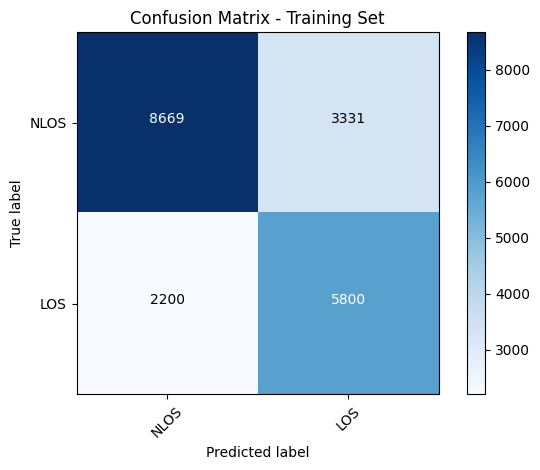

Confusion Matrix:
[[8669 3331]
 [2200 5800]]


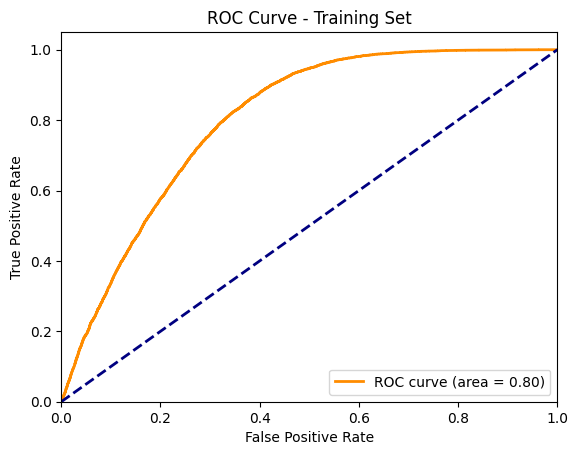

Metrics for Training Set:
Accuracy: 0.7235
Precision: 0.6352
Recall (Sensitivity): 0.7250
Specificity: 0.7224
F1 Score: 0.6771
ROC AUC: 0.8008
Log Loss: 0.5096


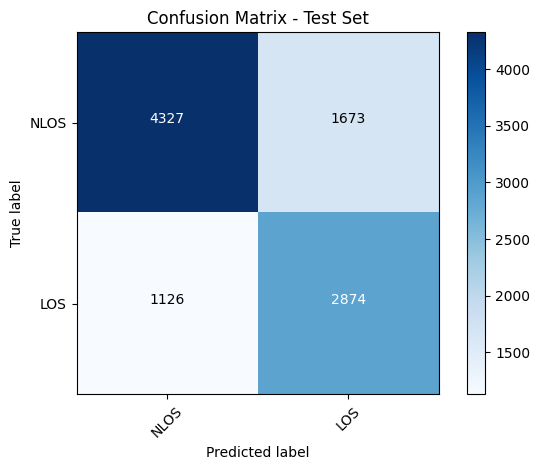

Confusion Matrix:
[[4327 1673]
 [1126 2874]]


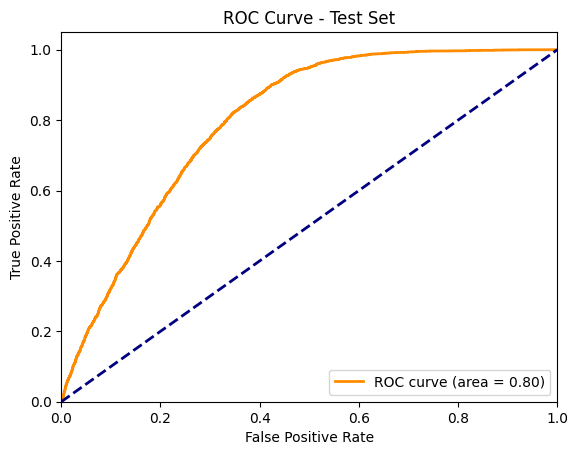

Metrics for Test Set:
Accuracy: 0.7201
Precision: 0.6321
Recall (Sensitivity): 0.7185
Specificity: 0.7212
F1 Score: 0.6725
ROC AUC: 0.7973
Log Loss: 0.5113


In [ ]:
# Concatenate full  the datasets in training and testing
# df_full = pd.concat([df_tdl_cdl, df_sionna_mimo])
# df_full_test = pd.concat([df_tdl_cdl_test, df_sionna_mimo_test])
df_full = df_tdl_cdl_siso
df_full_test = df_tdl_cdl_siso_test
# Preprocess the data
features, labels = preprocess_data(df_full)
features_test, labels_test = preprocess_data(df_full_test)
# Train the model and get predictions
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob, _ = train_mlp(features, labels, features_test, labels_test)

# Plot confusion matrix and ROC curve for training set
plot_confusion_matrix(y_train, y_train_pred, title='Confusion Matrix - Training Set')
plot_roc_curve(y_train, y_train_prob, title='ROC Curve - Training Set')

# Print metrics for training set
print("Metrics for Training Set:")
print_metrics(y_train, y_train_pred, y_train_prob)

# Plot confusion matrix and ROC curve for test set
plot_confusion_matrix(y_test, y_test_pred, title='Confusion Matrix - Test Set')
plot_roc_curve(y_test, y_test_prob, title='ROC Curve - Test Set')

# Print metrics for test set
print("Metrics for Test Set:")
print_metrics(y_test, y_test_pred, y_test_prob)


In [4]:
print("TDL")
df_full = df_tdl_cdl_siso
df_full_test = df_tdl_cdl_siso_test
features, labels = preprocess_data(df_full)
features_test, labels_test = preprocess_data(df_full_test)
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob,mlp = train_mlp(features, labels, features_test, labels_test)
print("Metrics for Test Set, -3-20db:")
print_metrics(y_test, y_test_pred, y_test_prob)
df_full_test = df_tdl_cdl_0db_siso_test
features_test, labels_test = preprocess_data(df_full_test)
y_tests = labels_test
y_test_pred = mlp.predict(features_test)
y_test_prob = mlp.predict_proba(features_test)[:, 1]
print("Metrics for Test Set, 0db:")
print_metrics(y_test, y_test_pred, y_test_prob)
df_full_test = df_tdl_cdl_5db_siso_test
features_test, labels_test = preprocess_data(df_full_test)
y_tests = labels_test
y_test_pred = mlp.predict(features_test)
y_test_prob = mlp.predict_proba(features_test)[:, 1]
print("Metrics for Test Set, 5db:")
print_metrics(y_test, y_test_pred, y_test_prob)
df_full_test = df_tdl_cdl_10db_siso_test
features_test, labels_test = preprocess_data(df_full_test)
y_tests = labels_test
y_test_pred = mlp.predict(features_test)
y_test_prob = mlp.predict_proba(features_test)[:, 1]
print("Metrics for Test Set, 10db:")
print_metrics(y_test, y_test_pred, y_test_prob)
df_full_test = df_tdl_cdl_15db_siso_test
features_test, labels_test = preprocess_data(df_full_test)
y_tests = labels_test
y_test_pred = mlp.predict(features_test)
y_test_prob = mlp.predict_proba(features_test)[:, 1]
print("Metrics for Test Set, 15db:")
print_metrics(y_test, y_test_pred, y_test_prob)


TDL


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

Metrics for Test Set, -3-20db:
Accuracy: 0.7201
Precision: 0.6321
Recall (Sensitivity): 0.7185
Specificity: 0.7212
F1 Score: 0.6725
ROC AUC: 0.7973
Log Loss: 0.5113
Metrics for Test Set, 0db:
Accuracy: 0.6867
Precision: 0.5876
Recall (Sensitivity): 0.7268
Specificity: 0.6600
F1 Score: 0.6498
ROC AUC: 0.7533
Log Loss: 0.5397


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

Metrics for Test Set, 5db:
Accuracy: 0.7070
Precision: 0.6003
Recall (Sensitivity): 0.8003
Specificity: 0.6448
F1 Score: 0.6860
ROC AUC: 0.7801
Log Loss: 0.5226
Metrics for Test Set, 10db:
Accuracy: 0.7431
Precision: 0.6554
Recall (Sensitivity): 0.7542
Specificity: 0.7357
F1 Score: 0.7014
ROC AUC: 0.8149
Log Loss: 0.4989


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

Metrics for Test Set, 15db:
Accuracy: 0.7367
Precision: 0.6782
Recall (Sensitivity): 0.6502
Specificity: 0.7943
F1 Score: 0.6639
ROC AUC: 0.8202
Log Loss: 0.4979


In [5]:
print("MIMO")
df_full = df_tdl_cdl_mimo
df_full_test = df_tdl_cdl_mimo_test
features, labels = preprocess_data(df_full)
features_test, labels_test = preprocess_data(df_full_test)
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob, mlp = train_mlp(features, labels, features_test, labels_test)
print("Metrics for Test Set, -3-20db:")
print_metrics(y_test, y_test_pred, y_test_prob)

df_full_test = df_tdl_cdl_0db_mimo_test
features_test, labels_test = preprocess_data(df_full_test)
y_tests = labels_test
y_test_pred = mlp.predict(features_test)
y_test_prob = mlp.predict_proba(features_test)[:, 1]
print("Metrics for Test Set, 0db:")
print_metrics(y_test, y_test_pred, y_test_prob)

df_full_test = df_tdl_cdl_5db_mimo_test
features_test, labels_test = preprocess_data(df_full_test)
y_tests = labels_test
y_test_pred = mlp.predict(features_test)
y_test_prob = mlp.predict_proba(features_test)[:, 1]
print("Metrics for Test Set, 5db:")
print_metrics(y_test, y_test_pred, y_test_prob)

df_full_test = df_tdl_cdl_10db_mimo_test
features_test, labels_test = preprocess_data(df_full_test)
y_tests = labels_test
y_test_pred = mlp.predict(features_test)
y_test_prob = mlp.predict_proba(features_test)[:, 1]
print("Metrics for Test Set, 10db:")
print_metrics(y_test, y_test_pred, y_test_prob)

df_full_test = df_tdl_cdl_15db_mimo_test
features_test, labels_test = preprocess_data(df_full_test)
y_tests = labels_test
y_test_pred = mlp.predict(features_test)
y_test_prob = mlp.predict_proba(features_test)[:, 1]
print("Metrics for Test Set, 15db:")
print_metrics(y_test, y_test_pred, y_test_prob)

MIMO


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

Metrics for Test Set, -3-20db:
Accuracy: 0.7799
Precision: 0.7668
Recall (Sensitivity): 0.6462
Specificity: 0.8690
F1 Score: 0.7014
ROC AUC: 0.8620
Log Loss: 0.4406
Metrics for Test Set, 0db:


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

Accuracy: 0.5909
Precision: 0.2429
Recall (Sensitivity): 0.0107
Specificity: 0.9777
F1 Score: 0.0206
ROC AUC: 0.4920
Log Loss: 0.6780


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column


Metrics for Test Set, 5db:
Accuracy: 0.7849
Precision: 0.7132
Recall (Sensitivity): 0.7732
Specificity: 0.7927
F1 Score: 0.7420
ROC AUC: 0.8636
Log Loss: 0.4518


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column


Metrics for Test Set, 10db:
Accuracy: 0.8441
Precision: 0.7831
Recall (Sensitivity): 0.8440
Specificity: 0.8442
F1 Score: 0.8124
ROC AUC: 0.9208
Log Loss: 0.3471
Metrics for Test Set, 15db:
Accuracy: 0.8701
Precision: 0.8177
Recall (Sensitivity): 0.8690
Specificity: 0.8708
F1 Score: 0.8426
ROC AUC: 0.9411
Log Loss: 0.3013


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column


In [6]:


# ---- TDL CDL SISO ----
print("TDL CDL SISO")
tdl_siso_results = []

df_full = df_tdl_cdl_siso
df_full_test_list = [
    ("-3-20db", df_tdl_cdl_siso_test),
    ("0db", df_tdl_cdl_0db_siso_test),
    ("5db", df_tdl_cdl_5db_siso_test),
    ("10db", df_tdl_cdl_10db_siso_test),
    ("15db", df_tdl_cdl_15db_siso_test),
]

features, labels = preprocess_data(df_full)
features_test, labels_test = preprocess_data(df_full_test_list[0][1])
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob, mlp = train_mlp(features, labels, features_test, labels_test)
metrics = get_metrics(y_test, y_test_pred, y_test_prob)
metrics['SNR'] = df_full_test_list[0][0]
tdl_siso_results.append(metrics)

for snr_name, df_snr in df_full_test_list[1:]:
    features_snr, labels_snr = preprocess_data(df_snr)
    y_test_pred = mlp.predict(features_snr)
    y_test_prob = mlp.predict_proba(features_snr)[:, 1]
    metrics = get_metrics(labels_snr, y_test_pred, y_test_prob)
    metrics['SNR'] = snr_name
    tdl_siso_results.append(metrics)

df_tdl_siso_results = pd.DataFrame(tdl_siso_results)
df_tdl_siso_results = df_tdl_siso_results[['SNR'] + [col for col in df_tdl_siso_results.columns if col != 'SNR']]
print(df_tdl_siso_results.to_string(index=False))


# ---- TDL CDL MIMO ----
print("\nTDL CDL MIMO")
tdl_mimo_results = []

df_full = df_tdl_cdl_mimo
df_full_test_list = [
    ("-3-20db", df_tdl_cdl_mimo_test),
    ("0db", df_tdl_cdl_0db_mimo_test),
    ("5db", df_tdl_cdl_5db_mimo_test),
    ("10db", df_tdl_cdl_10db_mimo_test),
    ("15db", df_tdl_cdl_15db_mimo_test),
]

features, labels = preprocess_data(df_full)
features_test, labels_test = preprocess_data(df_full_test_list[0][1])
y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob, mlp = train_mlp(features, labels, features_test, labels_test)
metrics = get_metrics(y_test, y_test_pred, y_test_prob)
metrics['SNR'] = df_full_test_list[0][0]
tdl_mimo_results.append(metrics)

for snr_name, df_snr in df_full_test_list[1:]:
    features_snr, labels_snr = preprocess_data(df_snr)
    y_test_pred = mlp.predict(features_snr)
    y_test_prob = mlp.predict_proba(features_snr)[:, 1]
    metrics = get_metrics(labels_snr, y_test_pred, y_test_prob)
    metrics['SNR'] = snr_name
    tdl_mimo_results.append(metrics)

df_tdl_mimo_results = pd.DataFrame(tdl_mimo_results)
df_tdl_mimo_results = df_tdl_mimo_results[['SNR'] + [col for col in df_tdl_mimo_results.columns if col != 'SNR']]
print(df_tdl_mimo_results.to_string(index=False))

TDL CDL SISO


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

    SNR  Accuracy  Precision  Recall  Specificity  F1 Score  ROC AUC  Log Loss
-3-20db    0.7201   0.632065 0.71850     0.721167  0.672517 0.797252  0.511333
    0db    0.6867   0.587629 0.72675     0.660000  0.649827 0.753295  0.539741
    5db    0.7070   0.600338 0.80025     0.644833  0.686027 0.780050  0.522628
   10db    0.7431   0.655442 0.75425     0.735667  0.701383 0.814909  0.498923
   15db    0.7367   0.678227 0.65025     0.794333  0.663944 0.820248  0.497883

TDL CDL MIMO


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

    SNR  Accuracy  Precision  Recall  Specificity  F1 Score  ROC AUC  Log Loss
-3-20db    0.7799   0.766835 0.64625     0.869000  0.701397 0.861963  0.440562
    0db    0.5909   0.242938 0.01075     0.977667  0.020589 0.492024  0.677993
    5db    0.7849   0.713166 0.77325     0.792667  0.741994 0.863608  0.451769
   10db    0.8441   0.783113 0.84400     0.844167  0.812417 0.920756  0.347137
   15db    0.8701   0.817690 0.86900     0.870833  0.842565 0.941113  0.301302


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column


In [7]:
import pandas as pd
from evaluation import get_metrics

cases = [
    {
        "name": "TDL SISO",
        "train": df_tdl_siso,
        "test": df_tdl_siso_test,
        "snr_tests": [
            ("0db", df_tdl_0db_siso_test),
            ("5db", df_tdl_5db_siso_test),
            ("10db", df_tdl_10db_siso_test),
            ("15db", df_tdl_15db_siso_test),
        ],
    },
    {
        "name": "CDL SISO",
        "train": df_cdl_siso,
        "test": df_cdl_siso_test,
        "snr_tests": [
            ("0db", df_cdl_0db_siso_test),
            ("5db", df_cdl_5db_siso_test),
            ("10db", df_cdl_10db_siso_test),
            ("15db", df_cdl_15db_siso_test),
        ],
    },
    {
        "name": "TDL MIMO",
        "train": df_tdl_mimo,
        "test": df_tdl_mimo_test,
        "snr_tests": [
            ("0db", df_tdl_0db_mimo_test),
            ("5db", df_tdl_5db_mimo_test),
            ("10db", df_tdl_10db_mimo_test),
            ("15db", df_tdl_15db_mimo_test),
        ],
    },
    {
        "name": "CDL MIMO",
        "train": df_cdl_mimo,
        "test": df_cdl_mimo_test,
        "snr_tests": [
            ("0db", df_cdl_0db_mimo_test),
            ("5db", df_cdl_5db_mimo_test),
            ("10db", df_cdl_10db_mimo_test),
            ("15db", df_cdl_15db_mimo_test),
        ],
    },
]


results = []

for case in cases:
    features, labels = preprocess_data(case["train"])
    features_test, labels_test = preprocess_data(case["test"])
    y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob, mlp = train_mlp(features, labels, features_test, labels_test)
    metrics = get_metrics(y_test, y_test_pred, y_test_prob)
    metrics['Case'] = case['name']
    metrics['SNR'] = '-3-20db'
    results.append(metrics)
    for snr_name, df_snr in case["snr_tests"]:
        features_snr, labels_snr = preprocess_data(df_snr)
        y_test_pred = mlp.predict(features_snr)
        y_test_prob = mlp.predict_proba(features_snr)[:, 1]
        metrics = get_metrics(labels_snr, y_test_pred, y_test_prob)
        metrics['Case'] = case['name']
        metrics['SNR'] = snr_name
        results.append(metrics)

df_results = pd.DataFrame(results)
cols = ['Case', 'SNR'] + [col for col in df_results.columns if col not in ['Case', 'SNR']]
df_results = df_results[cols]
print(df_results.to_string(index=False))

/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

    Case     SNR  Accuracy  Precision  Recall  Specificity  F1 Score  ROC AUC  Log Loss
TDL SISO -3-20db    0.8152   0.756435  0.7935     0.829667  0.774524 0.890692  0.406934
TDL SISO     0db    0.7956   0.762621  0.7100     0.852667  0.735370 0.875176  0.438634
TDL SISO     5db    0.8088   0.751445  0.7800     0.828000  0.765456 0.888953  0.419122
TDL SISO    10db    0.8150   0.747582  0.8115     0.817333  0.778231 0.890740  0.417560
TDL SISO    15db    0.8100   0.741490  0.8060     0.812667  0.772401 0.893042  0.416553
CDL SISO -3-20db    0.6584   0.573073  0.5725     0.715667  0.572786 0.730913  0.569212
CDL SISO     0db    0.6002   0.500560  0.2235     0.851333  0.309022 0.653558  0.608604
CDL SISO     5db    0.6266   0.526890  0.6515     0.610000  0.582607 0.692141  0.578783
CDL SISO    10db    0.6898   0.583800  0.7820     0.628333  0.668519 0.768231  0.548678
CDL SISO    15db    0.7002   0.620607  0.6445     0.737333  0.632328 0.777750  0.535224
TDL MIMO -3-20db    0.8374   0.8

/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to b

In [9]:
classifiers = {
    "MLP": train_mlp,
    "kNN": train_knn,
    "SVM": train_svm,
    "RF": train_rf,
}

results = []

for case in cases:
    features, labels = preprocess_data(case["train"])
    features_test, labels_test = preprocess_data(case["test"])
    for clf_name, clf_func in classifiers.items():
        y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob, clf = clf_func(features, labels, features_test, labels_test)
        metrics = get_metrics(y_test, y_test_pred, y_test_prob)
        metrics['Case'] = case['name']
        metrics['SNR'] = '-3-20db'
        metrics['Classifier'] = clf_name
        results.append(metrics)
        for snr_name, df_snr in case["snr_tests"]:
            features_snr, labels_snr = preprocess_data(df_snr)
            y_test_pred = clf.predict(features_snr)
            y_test_prob = clf.predict_proba(features_snr)[:, 1]
            metrics = get_metrics(labels_snr, y_test_pred, y_test_prob)
            metrics['Case'] = case['name']
            metrics['SNR'] = snr_name
            metrics['Classifier'] = clf_name
            results.append(metrics)

df_results = pd.DataFrame(results)
cols = ['Case', 'SNR', 'Classifier'] + [col for col in df_results.columns if col not in ['Case', 'SNR', 'Classifier']]
df_results = df_results[cols]
print(df_results.to_string(index=False))

/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

    Case     SNR Classifier  Accuracy  Precision  Recall  Specificity  F1 Score  ROC AUC  Log Loss
TDL SISO -3-20db        MLP    0.8152   0.756435  0.7935     0.829667  0.774524 0.890692  0.406934
TDL SISO     0db        MLP    0.7956   0.762621  0.7100     0.852667  0.735370 0.875176  0.438634
TDL SISO     5db        MLP    0.8088   0.751445  0.7800     0.828000  0.765456 0.888953  0.419122
TDL SISO    10db        MLP    0.8150   0.747582  0.8115     0.817333  0.778231 0.890740  0.417560
TDL SISO    15db        MLP    0.8100   0.741490  0.8060     0.812667  0.772401 0.893042  0.416553
TDL SISO -3-20db        kNN    0.7326   0.666499  0.6635     0.778667  0.664996 0.795147  1.743282
TDL SISO     0db        kNN    0.6866   0.640493  0.4935     0.815333  0.557470 0.735123  2.206273
TDL SISO     5db        kNN    0.7180   0.663164  0.5995     0.797000  0.629727 0.778795  1.780788
TDL SISO    10db        kNN    0.7500   0.671703  0.7335     0.761000  0.701243 0.815339  1.764588
TDL SISO  

/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

In [ ]:

# ---- TDL CDL SISO ----
print("TDL CDL SISO")
tdl_siso_results = []

df_full = df_tdl_cdl_siso
df_full_test_list = [
    ("-3-20db", df_tdl_cdl_siso_test),
    ("0db", df_tdl_cdl_0db_siso_test),
    ("5db", df_tdl_cdl_5db_siso_test),
    ("10db", df_tdl_cdl_10db_siso_test),
    ("15db", df_tdl_cdl_15db_siso_test),
]

features, labels = preprocess_data(df_full)
features_test, labels_test = preprocess_data(df_full_test_list[0][1])

for clf_name, clf_func in classifiers.items():
    y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob, clf = clf_func(features, labels, features_test, labels_test)
    metrics = get_metrics(y_test, y_test_pred, y_test_prob)
    metrics['SNR'] = df_full_test_list[0][0]
    metrics['Classifier'] = clf_name
    tdl_siso_results.append(metrics)
    for snr_name, df_snr in df_full_test_list[1:]:
        features_snr, labels_snr = preprocess_data(df_snr)
        y_test_pred = clf.predict(features_snr)
        y_test_prob = clf.predict_proba(features_snr)[:, 1]
        metrics = get_metrics(labels_snr, y_test_pred, y_test_prob)
        metrics['SNR'] = snr_name
        metrics['Classifier'] = clf_name
        tdl_siso_results.append(metrics)

df_tdl_siso_results = pd.DataFrame(tdl_siso_results)
df_tdl_siso_results = df_tdl_siso_results[['Classifier', 'SNR'] + [col for col in df_tdl_siso_results.columns if col not in ['Classifier', 'SNR']]]
print(df_tdl_siso_results.to_string(index=False))


# ---- TDL CDL MIMO ----
print("\nTDL CDL MIMO")
tdl_mimo_results = []

df_full = df_tdl_cdl_mimo
df_full_test_list = [
    ("-3-20db", df_tdl_cdl_mimo_test),
    ("0db", df_tdl_cdl_0db_mimo_test),
    ("5db", df_tdl_cdl_5db_migit stmo_test),
    ("10db", df_tdl_cdl_10db_mimo_test),
    ("15db", df_tdl_cdl_15db_mimo_test),
]

features, labels = preprocess_data(df_full)
features_test, labels_test = preprocess_data(df_full_test_list[0][1])

for clf_name, clf_func in classifiers.items():
    y_train, y_train_pred, y_train_prob, y_test, y_test_pred, y_test_prob, clf = clf_func(features, labels, features_test, labels_test)
    metrics = get_metrics(y_test, y_test_pred, y_test_prob)
    metrics['SNR'] = df_full_test_list[0][0]
    metrics['Classifier'] = clf_name
    tdl_mimo_results.append(metrics)
    for snr_name, df_snr in df_full_test_list[1:]:
        features_snr, labels_snr = preprocess_data(df_snr)
        y_test_pred = clf.predict(features_snr)
        y_test_prob = clf.predict_proba(features_snr)[:, 1]
        metrics = get_metrics(labels_snr, y_test_pred, y_test_prob)
        metrics['SNR'] = snr_name
        metrics['Classifier'] = clf_name
        tdl_mimo_results.append(metrics)

df_tdl_mimo_results = pd.DataFrame(tdl_mimo_results)
df_tdl_mimo_results = df_tdl_mimo_results[['Classifier', 'SNR'] + [col for col in df_tdl_mimo_results.columns if col not in ['Classifier', 'SNR']]]
print(df_tdl_mimo_results.to_string(index=False))

TDL CDL SISO


/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

Classifier     SNR  Accuracy  Precision  Recall  Specificity  F1 Score  ROC AUC  Log Loss
       MLP -3-20db    0.7201   0.632065 0.71850     0.721167  0.672517 0.797252  0.511333
       MLP     0db    0.6867   0.587629 0.72675     0.660000  0.649827 0.753295  0.539741
       MLP     5db    0.7070   0.600338 0.80025     0.644833  0.686027 0.780050  0.522628
       MLP    10db    0.7431   0.655442 0.75425     0.735667  0.701383 0.814909  0.498923
       MLP    15db    0.7367   0.678227 0.65025     0.794333  0.663944 0.820248  0.497883
       kNN -3-20db    0.6484   0.558938 0.57375     0.698167  0.566247 0.703654  1.745525
       kNN     0db    0.6260   0.537725 0.46325     0.734500  0.497717 0.658534  2.204042
       kNN     5db    0.6410   0.549184 0.57225     0.686833  0.560480 0.689902  1.930754
       kNN    10db    0.6689   0.574422 0.66475     0.671667  0.616294 0.721171  1.801656
       kNN    15db    0.6893   0.604347 0.64650     0.717833  0.624713 0.743499  1.689172
       SVM

/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_abs"] = features["mean"].apply(lambda x: abs(complex(x)))
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features["mean_phase"] = features["mean"].apply(lambda x: cmath.phase(complex(x)))    # remove the original mean column
/home/l2nguyen/long_nguyen_thesis/data_preprocessing.py:25: SettingWithCopyWarning: 
A value is trying to b

Classifier     SNR  Accuracy  Precision  Recall  Specificity  F1 Score  ROC AUC  Log Loss
       MLP -3-20db    0.7799   0.766835 0.64625     0.869000  0.701397 0.861963  0.440562
       MLP     0db    0.5909   0.242938 0.01075     0.977667  0.020589 0.492024  0.677993
       MLP     5db    0.7849   0.713166 0.77325     0.792667  0.741994 0.863608  0.451769
       MLP    10db    0.8441   0.783113 0.84400     0.844167  0.812417 0.920756  0.347137
       MLP    15db    0.8701   0.817690 0.86900     0.870833  0.842565 0.941113  0.301302
       kNN -3-20db    0.6791   0.604271 0.57300     0.749833  0.588220 0.736990  1.770492
       kNN     0db    0.5339   0.390888 0.29600     0.692500  0.336890 0.488305  2.077534
       kNN     5db    0.6603   0.592684 0.48200     0.779167  0.531642 0.719573  1.747655
       kNN    10db    0.7333   0.674522 0.64400     0.792833  0.658908 0.803956  1.570474
       kNN    15db    0.7704   0.678094 0.81100     0.743333  0.738616 0.849880  1.548367
       SVM